In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV

df = pd.read_csv('student_grade_ses_dataset.csv')

# Provide idea of the dataframe we are dealing with 
print(df.columns) 
print(df.info)

Index(['student_id', 'academic_year', 'survey_date', 'age', 'gender',
       'grade_level', 'school_type', 'residence_type', 'family_size',
       'num_siblings', 'single_parent_household', 'family_income_bracket',
       'annual_family_income_inr', 'father_education_level',
       'mother_education_level', 'father_occupation', 'mother_occupation',
       'has_internet_access', 'has_computer_or_laptop',
       'distance_to_school_km', 'scholarship_status', 'extra_tutoring',
       'parental_involvement_score', 'study_hours_per_week',
       'attendance_rate_pct', 'previous_year_grade_pct', 'final_grade_pct',
       'grade_class', 'at_risk_flag'],
      dtype='str')
<bound method DataFrame.info of       student_id academic_year survey_date  age  gender  grade_level  \
0      STU101529     2024-2025      6/3/25   16    Male           12   
1      STU107546     2022-2023      2/5/25   15    Male           10   
2      STU103737     2024-2025     21/3/25   14    Male            9   
3     

In [32]:
# Data Preprocessing 

# 1. Cleaning Duplicate Rows 
duplicates = df[df.duplicated()]
print("Duplicate Rows:")
print(duplicates)

row_count_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
row_count_after = len(df)
print(f"{row_count_before} rows -> {row_count_after} after removing duplicates")

# 2. Set 'student_id' as the index and drop it from the standard columns
is_all_unique = df['student_id'].is_unique
print(f"Column student_id uniqueness: {is_all_unique}")
df = df.set_index('student_id')


Duplicate Rows:
      student_id academic_year survey_date  age  gender  grade_level  \
2052   STU100247     2024-2025     10/3/25   13    Male            8   
2323   STU111139     2023-2024      5/3/25   17  Female           12   
4406   STU107482     2022-2023      1/5/25   14   Other            9   
5645   STU110619     2023-2024      8/5/25   11    Male            7   
5715   STU104160     2022-2023     12/5/25   13  Female            8   
5801   STU108370     2022-2023     22/3/25   18    Male           12   
6089   STU100191     2022-2023      8/3/25   15  Female           10   
6099   STU108270     2021-2022     16/4/25   12    Male            8   
7395   STU111279     2024-2025     19/4/25   15  Female            9   
7700   STU101857     2021-2022     10/5/25   14  Female           10   
7788   STU108388     2021-2022     10/4/25   18  Female           12   
7902   STU104036     2022-2023      3/4/25   14  Female           10   
7990   STU105705     2023-2024      7/3/25   15 

## TODO: What to do about missing rows  

In [33]:
# Check for missing values 
missing_rows = df[df.isna().any(axis=1)]
print("Rows with missing values:")
print(missing_rows) 

# Calculate percentage of missing cells per column 
col_missing_pct = df.isna().mean() * 100

# Filter to only show columns that actually have missing data, sorted highest to lowest
print("\nPercentage of missing values per column:")
print(col_missing_pct[col_missing_pct > 0].sort_values(ascending=False))

Rows with missing values:
           academic_year survey_date  age  gender  grade_level  \
student_id                                                       
STU107546      2022-2023      2/5/25   15    Male           10   
STU106506      2022-2023      7/4/25   18    Male           12   
STU103794      2023-2024     20/3/25   16  Female           12   
STU101647      2022-2023     13/3/25   14    Male           10   
STU105006      2021-2022      8/4/25   15    Male            9   
...                  ...         ...  ...     ...          ...   
STU108600      2024-2025      7/3/25   17    Male           11   
STU108332      2024-2025     19/4/25   16  Female           10   
STU106690      2024-2025      6/3/25   13  Female            9   
STU108524      2021-2022      8/4/25   13  Female            9   
STU110137      2023-2024     17/4/25   12  Female            7   

                 school_type residence_type  family_size  num_siblings  \
student_id                               

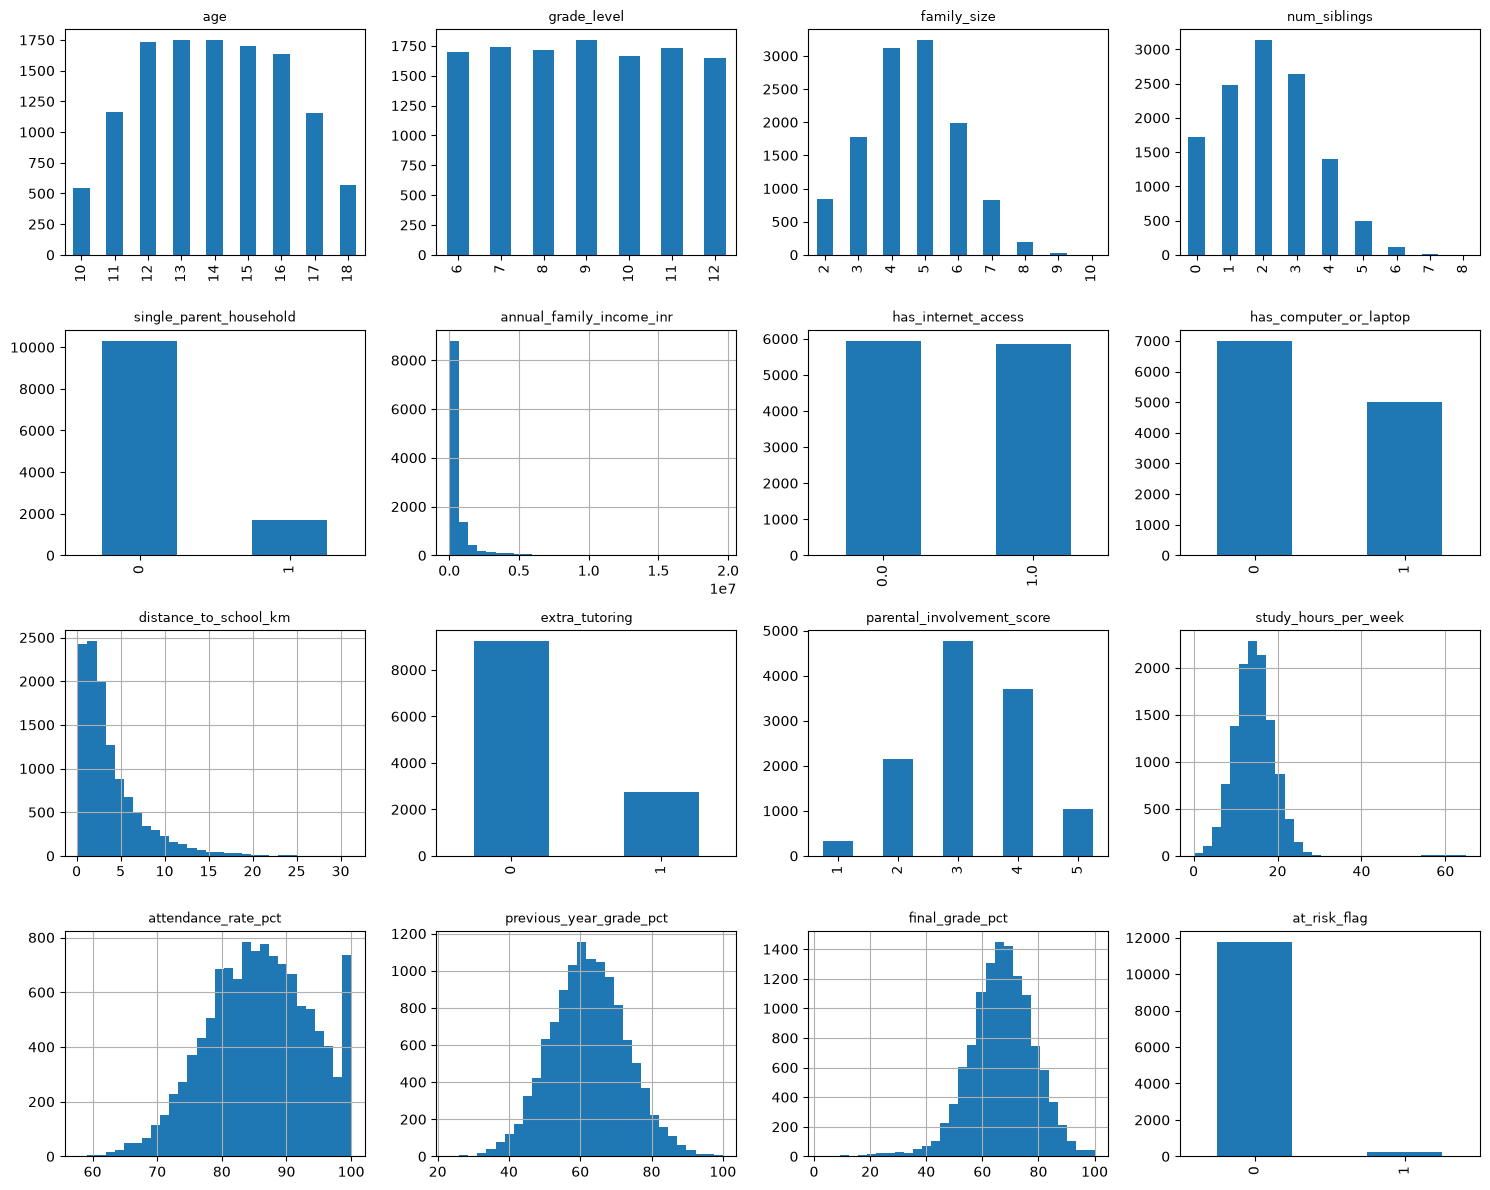

In [34]:
# Visualisation of predictors 

# Columns with only a few integer values get one bar per value
# Default histogram bins cut across the integers and leave gaps
num_cols = df.select_dtypes('number').columns

fig, axes = plt.subplots(4, 4, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    ax = axes[i]
    if df[col].nunique() <= 10:
        df[col].value_counts().sort_index().plot(kind='bar', ax=ax)
        ax.set_xlabel('')
    else:
        df[col].hist(bins=30, ax=ax)
    ax.set_title(col, fontsize=9)

plt.tight_layout()
plt.show()

## Skewed income column: annual_family_income_inr

From the histogram above, we can see that the annual_family_income_inr column is very right-skewed. In the data it ranges from about ₹60,000 to ₹19.6 million, a factor of more than 300. Most families sit near the low end and a few earn far more. On the raw scale, the few very rich families stretch the axis. This creates the problems of the ultra-wealthy outliers having too much influence in linear models. 

In such cases, a log transformation is ideal because algorithms like linear regression, logistics regression, K-means clustering and PCA are highly sensitive to extreme values and perform better when features are normally distributed. As the log is a monotonically increasing function, it naturally squashes massive numbers closer together while preserving the exact rank order of data.

In [35]:
# From the histogram above, heavily skewed income, so log-transform 
df['log_income'] = np.log(df.pop('annual_family_income_inr'))

## Schema Setup

Based off the variable histograms above, we can deduce which of the columns are discrete/continuous/categorical and we can form the column schema below. 

# TODO: CONSIDER CATEGORIAL PREDICTION

In [36]:
# Schema Setup 

TARGET_COL = 'final_grade_pct' 

CONTINUOUS_COLS = ['distance_to_school_km', 'study_hours_per_week', 'attendance_rate_pct',
                   'previous_year_grade_pct', 'log_income']

# Integer-coded, including 0/1 flags and the 1-5 parental involvement score
DISCRETE_COLS = ['age', 'grade_level', 'family_size', 'num_siblings', 'single_parent_household',
                 'has_internet_access', 'has_computer_or_laptop', 'extra_tutoring',
                 'parental_involvement_score']

# Text labels
CATEGORICAL_COLS = ['academic_year', 'gender', 'school_type', 'residence_type', 'family_income_bracket',
                    'father_education_level', 'mother_education_level', 'father_occupation',
                    'mother_occupation', 'scholarship_status']

NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS

In [37]:
X = df[PREDICTOR_COLS]
Y = df[TARGET_COL]
print('X:', X.shape, ' Y:', Y.shape)

X: (12000, 24)  Y: (12000,)


## Highly Correlated Predictors 



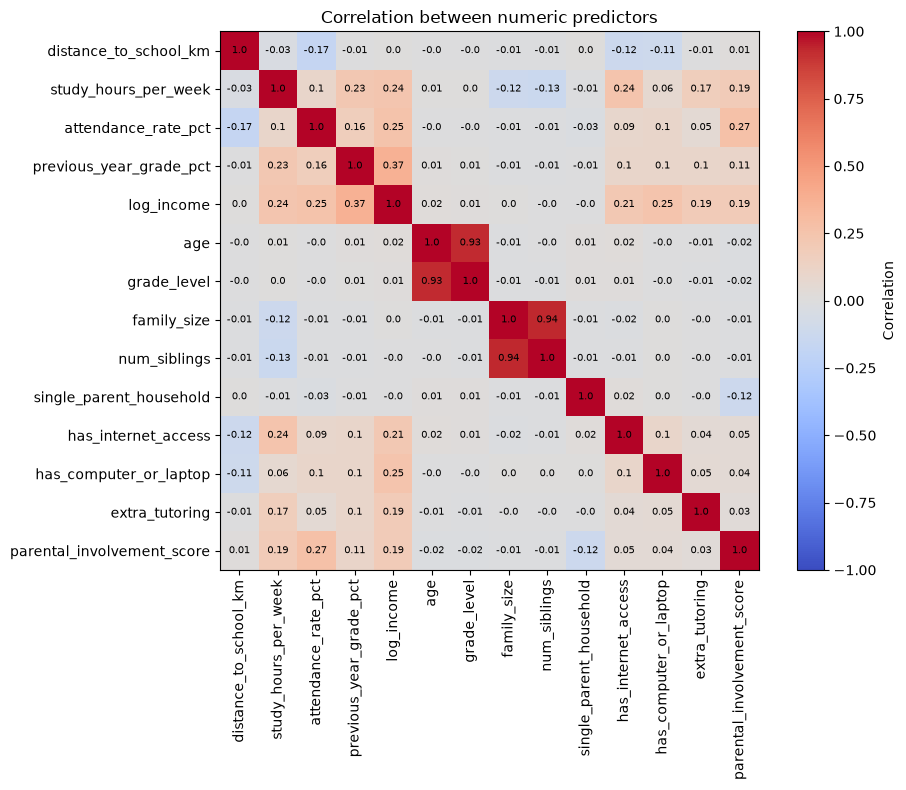

In [38]:
# Correlation heatmap of the numeric predictors
# (categorical columns are text, so they are left out here)
corr = X[NUMERIC_COLS].corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation')
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)

# write the correlation value in each square
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha='center', va='center', fontsize=7)

plt.title('Correlation between numeric predictors')
plt.tight_layout()
plt.show()

From the heatmap, most predictors are only weakly correlated with each other. Two pairs stand out:

- `age` and `grade_level` (r = 0.93): students in the same grade are mostly the same age.
- `family_size` and `num_siblings` (r = 0.94): more siblings means a bigger family.

Keeping both columns of a pair gives the linear models the same information twice, which makes the OLS coefficients unstable. So we drop one column from each pair:

- Keep `grade_level`, drop `age`. Grade level tells us which curriculum the student is in, and age within a grade adds little.
- Keep `family_size`, drop `num_siblings`. Family size also counts parents and other relatives, so it is the more general measure.

Both columns in each pair are almost uncorrelated with `final_grade_pct` (|r| about 0.00 for age/grade level and 0.05 for family size/siblings), so the choice is made on what the variable means rather than on the target. This also avoids using the target before the train/test split.

In [41]:
# Drop one predictor from each highly correlated pair
# age vs grade_level (r = 0.93) -> keep grade_level
# family_size vs num_siblings (r = 0.94) -> keep family_size
DROP_COLS = ['age', 'num_siblings']

DISCRETE_COLS = [c for c in DISCRETE_COLS if c not in DROP_COLS]
NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS

X = df[PREDICTOR_COLS]
print('Dropped:', DROP_COLS)
print('X:', X.shape)

Dropped: ['age', 'num_siblings']
X: (12000, 22)
